# cellassign benchmark: two datasets, two annotation scales

**Question.** How well does marker-based cluster annotation with `cellassign` work, compared with
its previous version and with other annotators, at a coarse scale (all cells) and at a fine scale
(one compartment re-processed and re-clustered)?

| Dataset | Coarse scale (all cells) | Fine scale (subset re-processed from counts) | Ground truth |
|---|---|---|---|
| PBMC CITE-seq, Hao et al. 2021 (day 0, 8 donors) | 8 lineages | T cells (9 subsets); myeloid (6 subsets) | Azimuth `celltype.l1/l2` (RNA + protein, WNN) |
| Human cortex, Siletti et al. 2023 (MFG / A46, 3 donors) | 7 classes | Interneurons (8 subclasses) | supercluster; Allen MTG subclass transferred by the authors |

**Methods** (all cluster-level methods use the same Leiden clusters):

- `cellassign v1` (1.0.1, defaults) and `cellassign v2` (this branch, defaults), same positive marker dictionaries;
- `cellassign v2 + negatives`: v2 with the same positive markers plus negative markers fixed a priori from
  the definition of each population (`bench/markers.py::NEGATIVES`, e.g. CD8A/CD8B for CD4 subsets, CD3 for NK,
  CCR7 for effector memory, VIP for Sncg);
- `cellassign v2 + negatives (curated)`: **post hoc** variant without the two negative sets that section 7
  of a first run showed to be transcribed in the target population (CD3D/CD3E in NK cells, FCGR3A in CD14
  monocytes). Chosen after seeing the results, so it is optimistic;
- `score_genes`: `scanpy.tl.score_genes` per category, cluster mean, arg-max;
- CellTypist (reference-based, majority voting over the same Leiden clusters);
- *oracle*: majority ground-truth label of each cluster, i.e. the ceiling for any one-label-per-cluster method.

**Metrics**: cell-level accuracy (unassigned = error), macro-F1 over ground-truth classes, fraction unassigned.

Marker dictionaries and label mappings are in `bench/markers.py`; they were fixed before running.

In [1]:
import importlib.metadata as md
import os
import warnings
from pathlib import Path

import pandas as pd

from bench import calibration, data, markers, methods, metrics, plots

warnings.filterwarnings("ignore", category=FutureWarning)
DATA = Path(os.environ.get("BENCH_DATA", "../data"))
MODELS = DATA / "celltypist_models"
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)
CELLTYPIST_MODELS = [
    "Immune_All_High",
    "Immune_All_Low",
    "Adult_Human_MTG",
    "Adult_Human_PrefrontalCortex",
]

data.download(DATA)  # ~1.4 GB the first time
data.download_celltypist_models(MODELS, CELLTYPIST_MODELS)


def version(package):
    try:
        return md.version(package)
    except md.PackageNotFoundError:
        return "source checkout"


{p: version(p) for p in ["cellassign", "scanpy", "anndata", "celltypist", "numpy", "pandas"]}

Out[1]: 
{'cellassign': 'source checkout',
 'scanpy': '1.11.5',
 'anndata': '0.12.19',
 'celltypist': '1.7.1',
 'numpy': '2.4.6',
 'pandas': '2.3.3'}


{'cellassign': 'source checkout',
 'scanpy': '1.11.5',
 'anndata': '0.12.19',
 'celltypist': '1.7.1',
 'numpy': '2.4.6',
 'pandas': '2.3.3'}

## 1. Data and the two scales

Workflow for every scale (`bench.data.preprocess`): genes in ≥10 cells, `normalize_total(1e4)` + `log1p`
(used by all annotators), 2,000 HVGs (batch-aware by donor), PCA (30 PCs) on scaled HVGs,
kNN graph (k = 15), Leiden resolution 2 (fine clustering, as the cellassign README recommends).
Fine scales are subset **by ground truth** and re-processed from counts, so first-level errors
do not propagate into the second level.

In [2]:
pbmc = data.preprocess(data.load_pbmc(DATA, timepoint=0))
brain = data.preprocess(data.load_siletti(DATA))

INTERNEURONS = ["MGE interneuron", "CGE interneuron", "LAMP5-LHX6 and Chandelier"]
datasets = {
    "pbmc_all": (pbmc, "truth_all"),
    "pbmc_T": (data.subset_and_reprocess(pbmc, pbmc.obs["truth_all"] == "T"), "truth_T"),
    "pbmc_myeloid": (
        data.subset_and_reprocess(pbmc, pbmc.obs["truth_all"].isin(["Mono", "DC"])),
        "truth_myeloid",
    ),
    "brain_all": (brain, "truth_all"),
    "brain_inh": (
        data.subset_and_reprocess(brain, brain.obs["supercluster"].isin(INTERNEURONS)),
        "truth_inh",
    ),
}
pd.DataFrame(
    {
        name: {
            "cells": a.n_obs,
            "scored cells": int(a.obs[t].notna().sum()),
            "classes": a.obs[t].nunique(),
            "Leiden clusters": a.obs["leiden"].nunique(),
        }
        for name, (a, t) in datasets.items()
    }
).T

Out[2]: 
              cells  scored cells  classes  Leiden clusters
pbmc_all      53144         53144        8               37
pbmc_T        22467         22352        9               28
pbmc_myeloid  19941         19941        6               26
brain_all     31065         30964        7               45
brain_inh      9794          9334        8               36


,cells,scored cells,classes,Leiden clusters
pbmc_all,53144,53144,8,37
pbmc_T,22467,22352,9,28
pbmc_myeloid,19941,19941,6,26
brain_all,31065,30964,7,45
brain_inh,9794,9334,8,36


## 2. Accuracy of every method at every scale

In [3]:
runs, summaries, per_class, runtimes = {}, [], {}, {}
for name, (adata, truth_col) in datasets.items():
    preds, v2_summary, runtime = methods.run_all(adata, markers.SCALES[name], MODELS)
    truth = adata.obs[truth_col]
    preds["oracle (cluster majority)"] = metrics.cluster_oracle(truth, adata.obs["leiden"])
    runs[name] = (preds, v2_summary)
    summaries.append(metrics.summarise(preds, truth).assign(scale=name).reset_index())
    per_class[name] = metrics.per_class_f1(preds, truth)
    runtimes[name] = runtime

summary = pd.concat(summaries, ignore_index=True)
summary.to_csv(RESULTS / "summary.csv", index=False)
summary.pivot(index="method", columns="scale", values="accuracy").round(3)

Out[3]: 
scale                                    brain_all  brain_inh  pbmc_T  pbmc_all  pbmc_myeloid
method                                                                                       
CellTypist Adult_Human_MTG                   0.996      0.986     NaN       NaN           NaN
CellTypist Adult_Human_PrefrontalCortex      0.998      0.899     NaN       NaN           NaN
CellTypist Immune_All_High                     NaN        NaN     NaN     0.985           NaN
CellTypist Immune_All_Low                      NaN        NaN   0.727       NaN         0.967
cellassign v1                                0.826      0.905   0.681     0.984         0.929
cellassign v2                                0.945      0.918   0.692     0.985         0.774
cellassign v2 + negatives                    0.986      0.921   0.745     0.886         0.545
cellassign v2 + negatives (curated)          0.986      0.921   0.745     0.985         0.767
oracle (cluster majority)                    0.998 

scale,brain_all,brain_inh,pbmc_T,pbmc_all,pbmc_myeloid
method,,,,,
CellTypist Adult_Human_MTG,0.996,0.986,NaN,NaN,NaN
CellTypist Adult_Human_PrefrontalCortex,0.998,0.899,NaN,NaN,NaN
CellTypist Immune_All_High,NaN,NaN,NaN,0.985,NaN
CellTypist Immune_All_Low,NaN,NaN,0.727,NaN,0.967
cellassign v1,0.826,0.905,0.681,0.984,0.929
cellassign v2,0.945,0.918,0.692,0.985,0.774
cellassign v2 + negatives,0.986,0.921,0.745,0.886,0.545
cellassign v2 + negatives (curated),0.986,0.921,0.745,0.985,0.767
oracle (cluster majority),0.998,0.986,0.826,0.985,0.977


In [4]:
summary.pivot(index="method", columns="scale", values="macro_F1").round(3)

Out[4]: 
scale                                    brain_all  brain_inh  pbmc_T  pbmc_all  pbmc_myeloid
method                                                                                       
CellTypist Adult_Human_MTG                   0.974      0.976     NaN       NaN           NaN
CellTypist Adult_Human_PrefrontalCortex      0.995      0.612     NaN       NaN           NaN
CellTypist Immune_All_High                     NaN        NaN     NaN     0.843           NaN
CellTypist Immune_All_Low                      NaN        NaN   0.425       NaN         0.789
cellassign v1                                0.949      0.865   0.526     0.839         0.767
cellassign v2                                0.967      0.840   0.589     0.843         0.764
cellassign v2 + negatives                    0.972      0.716   0.614     0.736         0.734
cellassign v2 + negatives (curated)          0.972      0.716   0.614     0.843         0.773
oracle (cluster majority)                    0.995 

scale,brain_all,brain_inh,pbmc_T,pbmc_all,pbmc_myeloid
method,,,,,
CellTypist Adult_Human_MTG,0.974,0.976,NaN,NaN,NaN
CellTypist Adult_Human_PrefrontalCortex,0.995,0.612,NaN,NaN,NaN
CellTypist Immune_All_High,NaN,NaN,NaN,0.843,NaN
CellTypist Immune_All_Low,NaN,NaN,0.425,NaN,0.789
cellassign v1,0.949,0.865,0.526,0.839,0.767
cellassign v2,0.967,0.840,0.589,0.843,0.764
cellassign v2 + negatives,0.972,0.716,0.614,0.736,0.734
cellassign v2 + negatives (curated),0.972,0.716,0.614,0.843,0.773
oracle (cluster majority),0.995,0.978,0.592,0.843,0.796


In [5]:
summary.pivot(index="method", columns="scale", values="unassigned").round(3)

Out[5]: 
scale                                    brain_all  brain_inh  pbmc_T  pbmc_all  pbmc_myeloid
method                                                                                       
CellTypist Adult_Human_MTG                   0.000      0.000     NaN       NaN           NaN
CellTypist Adult_Human_PrefrontalCortex      0.000      0.000     NaN       NaN           NaN
CellTypist Immune_All_High                     NaN        NaN     NaN     0.000           NaN
CellTypist Immune_All_Low                      NaN        NaN   0.000       NaN         0.000
cellassign v1                                0.171      0.012   0.019     0.001         0.006
cellassign v2                                0.052      0.012   0.044     0.000         0.190
cellassign v2 + negatives                    0.010      0.012   0.055     0.104         0.436
cellassign v2 + negatives (curated)          0.010      0.012   0.055     0.000         0.219
oracle (cluster majority)                    0.000 

scale,brain_all,brain_inh,pbmc_T,pbmc_all,pbmc_myeloid
method,,,,,
CellTypist Adult_Human_MTG,0.000,0.000,NaN,NaN,NaN
CellTypist Adult_Human_PrefrontalCortex,0.000,0.000,NaN,NaN,NaN
CellTypist Immune_All_High,NaN,NaN,NaN,0.000,NaN
CellTypist Immune_All_Low,NaN,NaN,0.000,NaN,0.000
cellassign v1,0.171,0.012,0.019,0.001,0.006
cellassign v2,0.052,0.012,0.044,0.000,0.190
cellassign v2 + negatives,0.010,0.012,0.055,0.104,0.436
cellassign v2 + negatives (curated),0.010,0.012,0.055,0.000,0.219
oracle (cluster majority),0.000,0.000,0.000,0.000,0.000


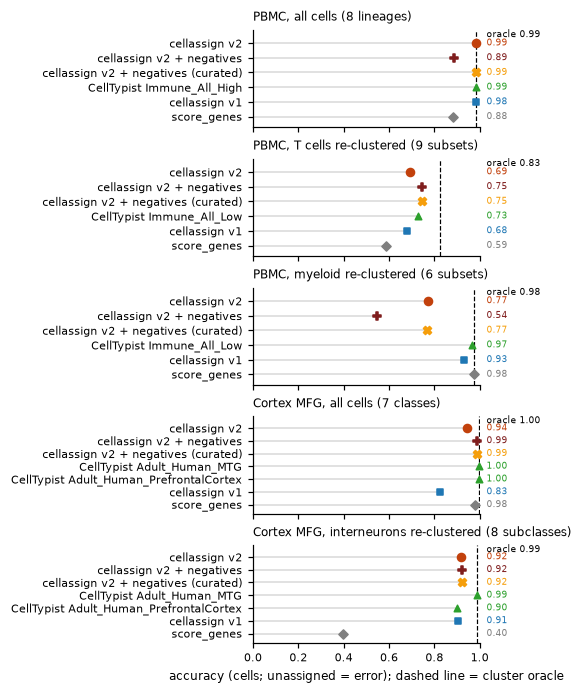

In [6]:
fig = plots.accuracy_dotplot(summary, "accuracy")
fig.savefig(RESULTS / "fig1_accuracy.png")

### Per-class F1 at the fine scales

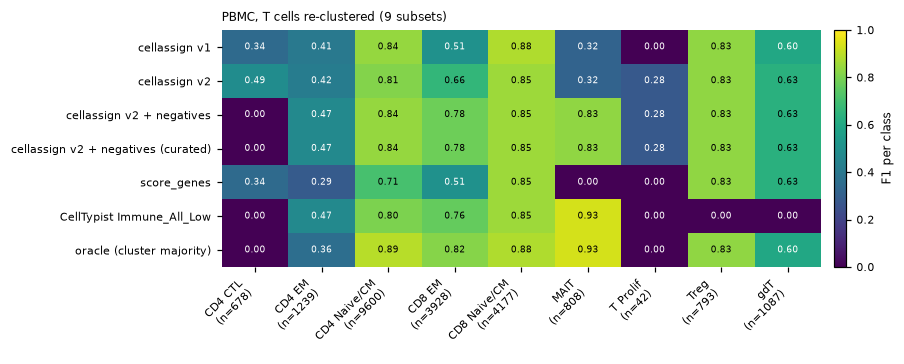

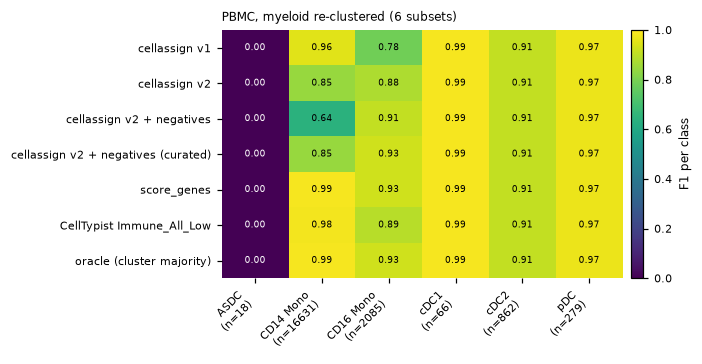

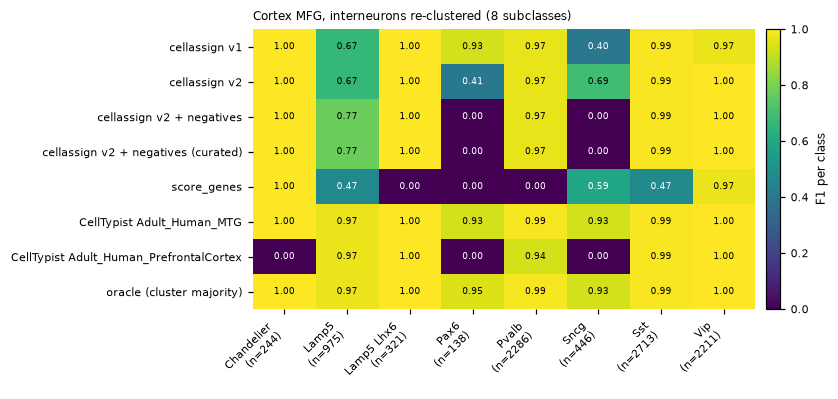

In [7]:
for name in ["pbmc_T", "pbmc_myeloid", "brain_inh"]:
    per_class[name].to_csv(RESULTS / f"per_class_f1_{name}.csv")
    fig = plots.f1_heatmap(per_class[name], plots.SCALE_TITLES[name])
    fig.savefig(RESULTS / f"fig2_f1_{name}.png")

### Effect of negative markers

Per-class F1 of `cellassign v2 + negatives` minus `cellassign v2` (positive values: the negative
markers help). Classes without negative markers can still change, because a penalised category stops
competing for other clusters.

In [8]:
delta = {
    name: (table.loc["cellassign v2 + negatives"] - table.loc["cellassign v2"]).round(2)
    for name, table in per_class.items()
}
for name, d in delta.items():
    print(name, d.to_dict())

pbmc_all {'B': 0.0, 'DC': 0.0, 'Eryth': 0.0, 'HSPC': 0.0, 'Mono': 0.0, 'NK': -0.85, 'Platelet': 0.0, 'T': 0.0}
pbmc_T {'CD4 CTL': -0.49, 'CD4 EM': 0.05, 'CD4 Naive/CM': 0.03, 'CD8 EM': 0.12, 'CD8 Naive/CM': 0.0, 'MAIT': 0.52, 'T Prolif': 0.0, 'Treg': 0.0, 'gdT': 0.0}
pbmc_myeloid {'ASDC': 0.0, 'CD14 Mono': -0.21, 'CD16 Mono': 0.03, 'cDC1': 0.0, 'cDC2': 0.0, 'pDC': 0.0}
brain_all {'Astrocyte': 0.0, 'Excitatory': 0.04, 'Inhibitory': -0.0, 'Microglia': 0.0, 'OPC': 0.0, 'Oligodendrocyte': 0.0, 'Vascular': 0.0}
brain_inh {'Chandelier': 0.0, 'Lamp5': 0.11, 'Lamp5 Lhx6': 0.0, 'Pax6': -0.41, 'Pvalb': 0.0, 'Sncg': -0.69, 'Sst': 0.0, 'Vip': -0.0}


## 3. Which v2 changes matter? (ablation)

Each v2 component is switched off in turn. `accuracy_argmax` picks the best category of every
cluster without any threshold (quality of the ranking); `accuracy` uses the default `min_score`.

In [9]:
ablation = pd.concat(
    [
        calibration.ablation(a, markers.SCALES[n], t).assign(scale=n)
        for n, (a, t) in datasets.items()
    ]
)
ablation.to_csv(RESULTS / "ablation.csv", index=False)
ablation.pivot(index="config", columns="scale", values="accuracy_argmax").round(3)

Out[9]: 
scale                   brain_all  brain_inh  pbmc_T  pbmc_all  pbmc_myeloid
config                                                                      
+ marker weights            0.996      0.893   0.690     0.985         0.935
+ negative markers          0.986      0.931   0.758     0.889         0.599
- balanced percentiles      0.996      0.929   0.660     0.985         0.797
- null correction           0.996      0.929   0.726     0.985         0.935
- smoothing                 0.996      0.888   0.657     0.971         0.962
v2 all off                  0.996      0.929   0.660     0.985         0.797
v2 default                  0.996      0.929   0.726     0.985         0.935


scale,brain_all,brain_inh,pbmc_T,pbmc_all,pbmc_myeloid
config,,,,,
+ marker weights,0.996,0.893,0.690,0.985,0.935
+ negative markers,0.986,0.931,0.758,0.889,0.599
- balanced percentiles,0.996,0.929,0.660,0.985,0.797
- null correction,0.996,0.929,0.726,0.985,0.935
- smoothing,0.996,0.888,0.657,0.971,0.962
v2 all off,0.996,0.929,0.660,0.985,0.797
v2 default,0.996,0.929,0.726,0.985,0.935


In [10]:
ablation.pivot(index="config", columns="scale", values="accuracy").round(3)

Out[10]: 
scale                   brain_all  brain_inh  pbmc_T  pbmc_all  pbmc_myeloid
config                                                                      
+ marker weights            0.945      0.867   0.655     0.985         0.774
+ negative markers          0.986      0.921   0.745     0.886         0.545
- balanced percentiles      0.693      0.918   0.647     0.985         0.501
- null correction           0.996      0.929   0.726     0.985         0.861
- smoothing                 0.752      0.875   0.516     0.971         0.671
v2 all off                  0.953      0.929   0.660     0.985         0.674
v2 default                  0.945      0.918   0.692     0.985         0.774


scale,brain_all,brain_inh,pbmc_T,pbmc_all,pbmc_myeloid
config,,,,,
+ marker weights,0.945,0.867,0.655,0.985,0.774
+ negative markers,0.986,0.921,0.745,0.886,0.545
- balanced percentiles,0.693,0.918,0.647,0.985,0.501
- null correction,0.996,0.929,0.726,0.985,0.861
- smoothing,0.752,0.875,0.516,0.971,0.671
v2 all off,0.953,0.929,0.660,0.985,0.674
v2 default,0.945,0.918,0.692,0.985,0.774


### Should the null model choose the category, or only accept it?

Arg-max accuracy of four rules to pick the category: the raw score, the raw score minus the null,
the null-normalised excess and a z-score against the control gene sets. v2 uses `raw` to choose and
the null only to accept or reject.

In [11]:
argmax = pd.DataFrame(
    {
        n: calibration.argmax_accuracy(
            calibration.cluster_tables(a, markers.SCALES[n]["markers"]),
            markers.SCALES[n]["to_eval"],
            a.obs[t],
            a.obs["leiden"],
        )
        for n, (a, t) in datasets.items()
    }
)
argmax.to_csv(RESULTS / "argmax_rules.csv")
argmax.round(3)

Out[11]: 
                   pbmc_all  pbmc_T  pbmc_myeloid  brain_all  brain_inh
raw                   0.985   0.726         0.935      0.996      0.929
raw - null            0.985   0.702         0.935      0.996      0.868
normalised excess     0.985   0.694         0.935      0.996      0.929
z                     0.774   0.727         0.935      0.996      0.898


,pbmc_all,pbmc_T,pbmc_myeloid,brain_all,brain_inh
raw,0.985,0.726,0.935,0.996,0.929
raw - null,0.985,0.702,0.935,0.996,0.868
normalised excess,0.985,0.694,0.935,0.996,0.929
z,0.774,0.727,0.935,0.996,0.898


## 4. Does `min_score` detect cell types missing from the dictionary?

Each ground-truth class (≥ 50 cells) is removed from the marker dictionary in turn. A good
threshold leaves the removed type `unassigned` while keeping the other cells correctly labelled.
Results are averaged over removed classes. Two acceptance rules are compared: the v2 default
(null-normalised confidence ≥ `min_score`, default 0.3) and the raw score (`null_correction=False`,
default 0.6). The category chosen for each cluster is the same under both rules.

In [12]:
novel = pd.concat(
    [
        calibration.novel_type_experiment(a, markers.SCALES[n], t).assign(scale=n)
        for n, (a, t) in datasets.items()
    ]
)
novel.to_csv(RESULTS / "novel_type.csv", index=False)
(
    novel.groupby(["rule", "min_score", "scale"])[["novel_unassigned", "known_accuracy"]]
    .mean()
    .unstack("scale")
    .round(3)
)

Out[12]: 
                          novel_unassigned                                        known_accuracy                                       
scale                            brain_all brain_inh pbmc_T pbmc_all pbmc_myeloid      brain_all brain_inh pbmc_T pbmc_all pbmc_myeloid
rule            min_score                                                                                                              
null-normalised 0.0                  0.385     0.151  0.071    0.172        0.372          0.997     0.928  0.742    0.987        0.940
                0.1                  0.430     0.232  0.121    0.277        0.408          0.997     0.928  0.738    0.987        0.883
                0.2                  0.615     0.361  0.220    0.543        0.771          0.997     0.928  0.734    0.987        0.883
                0.3                  0.655     0.481  0.263    0.624        0.785          0.952     0.914  0.703    0.987        0.845
                0.4                  0

novel_unassigned                                        known_accuracy                                       
scale                            brain_all brain_inh pbmc_T pbmc_all pbmc_myeloid      brain_all brain_inh pbmc_T pbmc_all pbmc_myeloid
rule            min_score                                                                                                              
null-normalised 0.0                  0.385     0.151  0.071    0.172        0.372          0.997     0.928  0.742    0.987        0.940
                0.1                  0.430     0.232  0.121    0.277        0.408          0.997     0.928  0.738    0.987        0.883
                0.2                  0.615     0.361  0.220    0.543        0.771          0.997     0.928  0.734    0.987        0.883
                0.3                  0.655     0.481  0.263    0.624        0.785          0.952     0.914  0.703    0.987        0.845
                0.4                  0.994     0.591  0.408    0.781        0.790          0.793     0.890  0.622    0.986        0.685
                0.5                  0.997     0.600  0.758    0.798        0.794          0.651     0.756  0.581    0.909        0.579
                0.6                  0.997     0.667  0.834    0.801        0.995          0.481     0.571  0.475    0.714        0.493
raw             0.0                  0.000     0.000  0.000    0.000        0.000          0.997     0.928  0.748    0.987        0.951
                0.5                  0.783     0.000  0.000    0.247        0.106          0.997     0.928  0.748    0.987        0.950
                0.6                  0.978     0.245  0.174    0.512        0.479          0.997     0.928  0.740    0.987        0.879
                0.7                  0.994     0.472  0.319    0.702        0.789          0.948     0.890  0.716    0.986        0.721
                0.8                  0.997     0.665  0.776    0.934        0.994          0.643     0.661  0.496    0.720        0.487
                0.9                  0.997     0.995  0.995    0.948        0.997          0.149     0.134  0.060    0.634        0.261

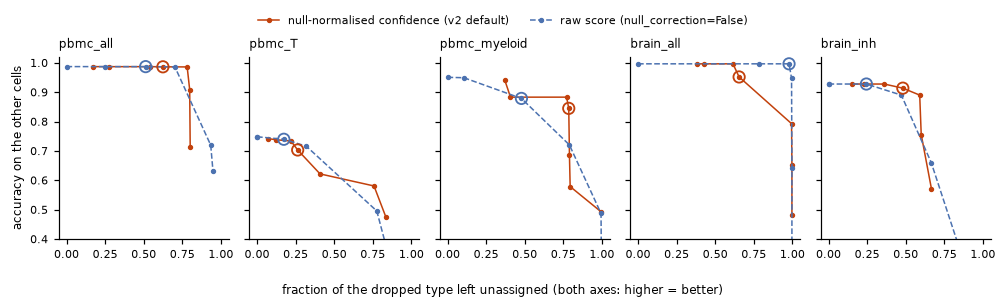

In [13]:
fig = plots.novelty_tradeoff(novel, calibration.DEFAULTS)
fig.savefig(RESULTS / "fig3_novel_type.png")

### A non-specific category

A "category" made only of housekeeping genes (ACTB, GAPDH, MALAT1, TPT1, EEF1A1, B2M) should never
be accepted. Fraction of cells that get this label when it is the only category (lower is better).

In [14]:
nonspecific = pd.concat(
    [calibration.nonspecific_category(a).assign(scale=n) for n, (a, _) in datasets.items()]
)
nonspecific.to_csv(RESULTS / "nonspecific_category.csv", index=False)
nonspecific.pivot(
    index=["rule", "min_score"], columns="scale", values="false_positive_cells"
).round(3)

Out[14]: 
scale                      brain_all  brain_inh  pbmc_T  pbmc_all  pbmc_myeloid
rule            min_score                                                      
null-normalised 0.0            0.346      0.581   0.358     0.385         0.389
                0.1            0.256      0.409   0.072     0.191         0.023
                0.2            0.111      0.161   0.000     0.038         0.021
                0.3            0.033      0.067   0.000     0.000         0.015
                0.4            0.015      0.025   0.000     0.000         0.000
                0.5            0.001      0.000   0.000     0.000         0.000
                0.6            0.001      0.000   0.000     0.000         0.000
raw             0.0            1.000      1.000   1.000     1.000         1.000
                0.5            0.744      0.887   0.629     0.750         0.794
                0.6            0.201      0.364   0.086     0.054         0.069
                0.7           

scale                      brain_all  brain_inh  pbmc_T  pbmc_all  pbmc_myeloid
rule            min_score                                                      
null-normalised 0.0            0.346      0.581   0.358     0.385         0.389
                0.1            0.256      0.409   0.072     0.191         0.023
                0.2            0.111      0.161   0.000     0.038         0.021
                0.3            0.033      0.067   0.000     0.000         0.015
                0.4            0.015      0.025   0.000     0.000         0.000
                0.5            0.001      0.000   0.000     0.000         0.000
                0.6            0.001      0.000   0.000     0.000         0.000
raw             0.0            1.000      1.000   1.000     1.000         1.000
                0.5            0.744      0.887   0.629     0.750         0.794
                0.6            0.201      0.364   0.086     0.054         0.069
                0.7            0.004      0.025   0.000     0.000         0.000
                0.8            0.000      0.000   0.000     0.000         0.000
                0.9            0.000      0.000   0.000     0.000         0.000

## 5. Are the v2 confidence metrics informative?

A cluster is *correct* when its v2 label equals its majority ground-truth label. AUROC of each
metric for separating correct from wrong clusters (0.5 = uninformative).

In [15]:
auroc, cluster_tables = {}, {}
for name, (adata, truth_col) in datasets.items():
    auroc[name], cluster_tables[name] = metrics.confidence_auroc(
        runs[name][1]["cellassign v2"], adata.obs[truth_col], adata.obs["leiden"]
    )
auroc = pd.DataFrame(auroc)
auroc.to_csv(RESULTS / "confidence_auroc.csv")
counts = pd.DataFrame(
    {
        n: {"clusters": len(t), "correct": int(t["correct"].sum())}
        for n, t in cluster_tables.items()
    }
)
pd.concat([counts, auroc.round(2)])

Out[15]: 
               pbmc_all  pbmc_T  pbmc_myeloid  brain_all  brain_inh
clusters           37.0   26.00         23.00      41.00      35.00
correct            37.0   18.00         20.00      40.00      32.00
score               NaN    0.66          0.57       0.18       0.33
margin              NaN    0.67          0.73       0.98       0.60
loo_stability       NaN    0.68          0.61       0.46       0.69


,pbmc_all,pbmc_T,pbmc_myeloid,brain_all,brain_inh
clusters,37.0,26.00,23.00,41.00,35.00
correct,37.0,18.00,20.00,40.00,32.00
score,NaN,0.66,0.57,0.18,0.33
margin,NaN,0.67,0.73,0.98,0.60
loo_stability,NaN,0.68,0.61,0.46,0.69


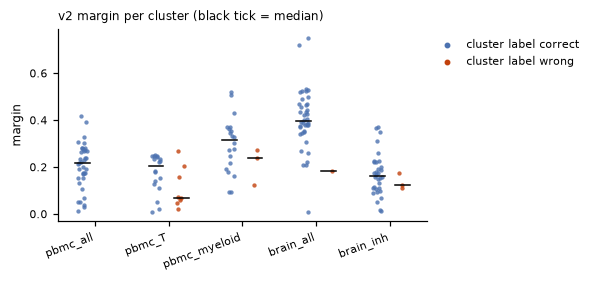

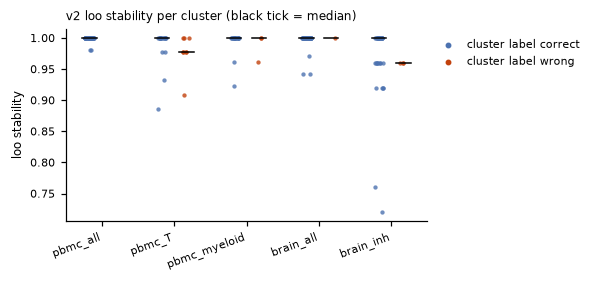

In [16]:
for metric in ["margin", "loo_stability"]:
    fig = plots.confidence_strip(cluster_tables, metric)
    fig.savefig(RESULTS / f"fig4_{metric}.png")

## 6. Runtime (seconds, this machine)

In [17]:
runtime = pd.DataFrame(runtimes).round(1)
runtime.to_csv(RESULTS / "runtime.csv")
runtime

Out[17]: 
                                         pbmc_all  pbmc_T  pbmc_myeloid  brain_all  brain_inh
CellTypist Adult_Human_MTG                    NaN     NaN           NaN        6.4        3.8
CellTypist Adult_Human_PrefrontalCortex       NaN     NaN           NaN        5.7        3.3
CellTypist Immune_All_High                    8.1     NaN           NaN        NaN        NaN
CellTypist Immune_All_Low                     NaN     4.7           4.3        NaN        NaN
cellassign v1                                 2.2     1.2           0.8        2.3        1.7
cellassign v2                                28.7     9.0           6.9       19.3        3.6
cellassign v2 + negatives                    27.2    10.1           7.9       16.1        3.8
cellassign v2 + negatives (curated)          27.0     9.9           7.4       18.0        3.8
score_genes                                  20.5     4.7           5.5       21.4        5.3


,pbmc_all,pbmc_T,pbmc_myeloid,brain_all,brain_inh
CellTypist Adult_Human_MTG,NaN,NaN,NaN,6.4,3.8
CellTypist Adult_Human_PrefrontalCortex,NaN,NaN,NaN,5.7,3.3
CellTypist Immune_All_High,8.1,NaN,NaN,NaN,NaN
CellTypist Immune_All_Low,NaN,4.7,4.3,NaN,NaN
cellassign v1,2.2,1.2,0.8,2.3,1.7
cellassign v2,28.7,9.0,6.9,19.3,3.6
cellassign v2 + negatives,27.2,10.1,7.9,16.1,3.8
cellassign v2 + negatives (curated),27.0,9.9,7.4,18.0,3.8
score_genes,20.5,4.7,5.5,21.4,5.3


## 7. Which negative markers help?

Diagnostic, not used to change the dictionaries: the negative markers of one category are removed
at a time. `delta` > 0 means they improve accuracy; `delta` < 0 means they hurt, typically because
the "negative" gene is transcribed in the target population even if the protein is absent.

In [18]:
negatives = pd.concat(
    [
        calibration.negative_marker_diagnostic(a, markers.SCALES[n], t).assign(scale=n)
        for n, (a, t) in datasets.items()
    ],
    ignore_index=True,
)
negatives.to_csv(RESULTS / "negative_marker_diagnostic.csv", index=False)
negatives[
    ["scale", "category", "negatives", "accuracy_all_negatives", "accuracy_without", "delta"]
].round(3)

Out[18]: 
           scale      category         negatives  accuracy_all_negatives  accuracy_without  delta
0       pbmc_all            NK        CD3D, CD3E                   0.886             0.985 -0.100
1       pbmc_all   Plasmablast             MS4A1                   0.886             0.886  0.000
2         pbmc_T  CD4 Naive/CM        CD8A, CD8B                   0.745             0.711  0.034
3         pbmc_T        CD4 EM  CD8A, CD8B, CCR7                   0.745             0.634  0.111
4         pbmc_T       CD4 CTL        CD8A, CD8B                   0.745             0.620  0.125
5         pbmc_T          Treg        CD8A, CD8B                   0.745             0.708  0.037
6         pbmc_T  CD8 Naive/CM               CD4                   0.745             0.709  0.036
7         pbmc_T        CD8 EM         CD4, CCR7                   0.745             0.749 -0.003
8         pbmc_T          MAIT              TRDC                   0.745             0.722  0.023
9   pbmc_m

,scale,category,negatives,accuracy_all_negatives,accuracy_without,delta
0,pbmc_all,NK,"CD3D, CD3E",0.886,0.985,-0.100
1,pbmc_all,Plasmablast,MS4A1,0.886,0.886,0.000
2,pbmc_T,CD4 Naive/CM,"CD8A, CD8B",0.745,0.711,0.034
3,pbmc_T,CD4 EM,"CD8A, CD8B, CCR7",0.745,0.634,0.111
4,pbmc_T,CD4 CTL,"CD8A, CD8B",0.745,0.620,0.125
5,pbmc_T,Treg,"CD8A, CD8B",0.745,0.708,0.037
6,pbmc_T,CD8 Naive/CM,CD4,0.745,0.709,0.036
7,pbmc_T,CD8 EM,"CD4, CCR7",0.745,0.749,-0.003
8,pbmc_T,MAIT,TRDC,0.745,0.722,0.023
9,pbmc_myeloid,CD14 Mono,FCGR3A,0.545,0.767,-0.222


## Caveats

- Ground truth is itself computational: Azimuth labels (RNA + protein) for PBMC; for the cortex,
  superclusters and an Allen MTG label transferred by Siletti et al. The `Adult_Human_MTG` CellTypist
  model is trained on the same Allen taxonomy, which favours it on `brain_inh`.
- CellTypist `Immune_All_*` models were trained on other datasets; vocabulary mismatches are resolved
  with the explicit mapping in `bench/markers.py` (labels without equivalent count as errors).
- Fine scales are subset with the ground truth, not with the first-level prediction.
- Marker dictionaries are literature-based starting points; the cellassign methods are only as good as them.
  Negative markers were added after the first benchmark run, from population definitions, without iterating
  on the results; they are still not independent of having seen where v2 failed.
- One clustering resolution and one seed; one donor batch handling (none beyond batch-aware HVGs).